<a href="https://colab.research.google.com/github/ericwuestewald/tree_birds/blob/main/scripts/3_bbs_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Set working directory
setwd("/content/drive/MyDrive/data_projects/tree_birds")

# Confirm
getwd()

[1] "/content/drive/MyDrive/data_projects/tree_birds"

In [2]:
#load libraries
library(ggplot2)
library(tidyverse)
library(dplyr)


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.2     ✔ tidyr     1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


**Calculate Total Tree Cover Loss 2001-2025**

In [3]:
#load datasets
df_trees <- read.csv("/content/drive/MyDrive/data_projects/tree_birds/clean_data/tree_loss_data_2001-2025.csv")
bbs_data <- read.csv("/content/drive/MyDrive/data_projects/tree_birds/clean_data/us_state_bird_abundance_by_forest_loss_2001-2025.csv")

In [4]:
#filter out total us tree cover loss dataset
df_us_trees <- df_trees %>%
filter(common_region == "United States")

#add total us tree cover loss 2001-2025
sum_us_trees <-
capture.output(
  cat("Total US Tree Cover Loss 2001-2025 (hectares):", sum(df_us_trees$yearly_loss_ha), "\n"),
  cat("Temporary US Tree Cover Loss 2001-2025 (hectares):", sum(df_us_trees$temp_tc_loss_ha), "\n"),
  cat("Permanent US Tree Cover Loss 2001-2025 (hectares):", sum(df_us_trees$perm_tc_loss_ha), "\n")
)

#filter out total SE tree cover loss dataset
df_se_trees <- df_trees %>%
filter(common_region %in% c("Georgia", "Texas", "North Carolina", "Florida", "Arkansas", "Alabama", "Virginia", "Mississippi", "Missouri", "South Carolina", "Tennessee"))

#add total SE tree cover loss 2001-2025
sum_se_trees <-
capture.output(
  cat("Total SE Tree Cover Loss 2001-2025 (hectares):", sum(df_se_trees$yearly_loss_ha), "\n"),
  cat("Temporary SE Tree Cover Loss 2001-2025 (hectares):", sum(df_se_trees$temp_tc_loss_ha), "\n"),
  cat("Permanent SE Tree Cover Loss 2001-2025 (hectares):", sum(df_se_trees$perm_tc_loss_ha), "\n")
)

sum_us_trees
sum_se_trees

[1] "Total US Tree Cover Loss 2001-2025 (hectares): 51036106 "    
[2] "Temporary US Tree Cover Loss 2001-2025 (hectares): 46862299 "
[3] "Permanent US Tree Cover Loss 2001-2025 (hectares): 4020348 "

[1] "Total SE Tree Cover Loss 2001-2025 (hectares): 23380338 "    
[2] "Temporary SE Tree Cover Loss 2001-2025 (hectares): 20609658 "
[3] "Permanent SE Tree Cover Loss 2001-2025 (hectares): 2720948 "

**Graphing Southeastern Birds by Taxonomic Order**

In [5]:
#Filter out full southeast data
bbs_data_se <- bbs_data %>%
  filter(common_region %in% c("Georgia", "Texas", "North Carolina", "Florida", "Arkansas", "Alabama", "Virginia", "Mississippi", "Missouri", "South Carolina", "Tennessee,"))

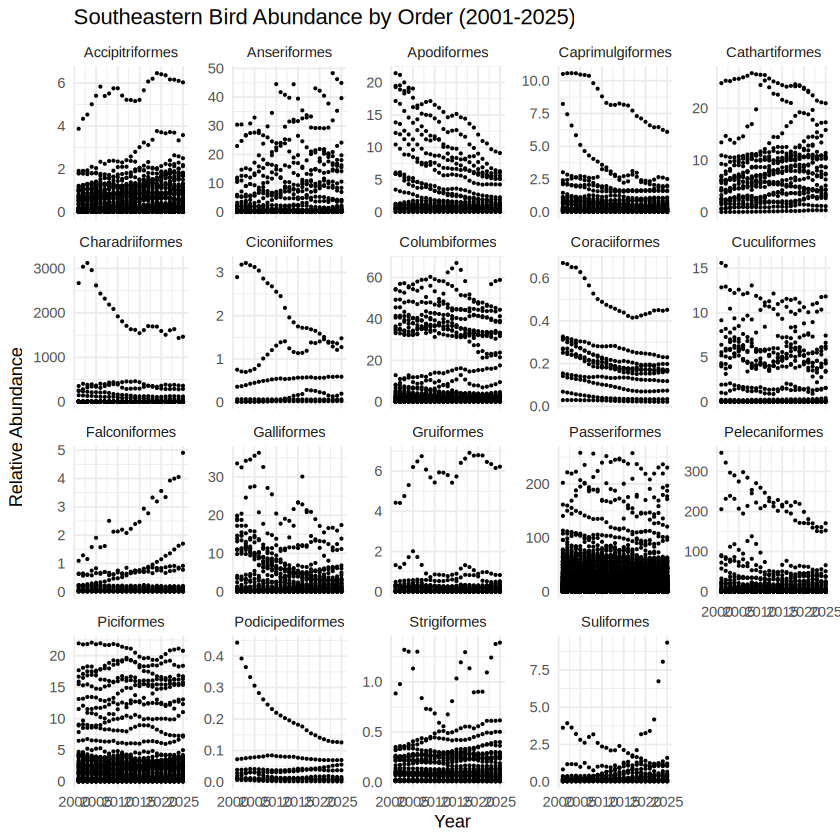

In [ ]:
#Divide by taxonomic order
ggplot(bbs_data_se, aes(y = relative_abundance, x = year)) +
  geom_point(size = .5) +
  facet_wrap(~order, scales = "free_y") +
  theme_minimal() +
  labs (title = "Southeastern Bird Abundance by Order (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Southeastern Hawks, Eagles, Kites, and Allies Abundance (2001-2025)"

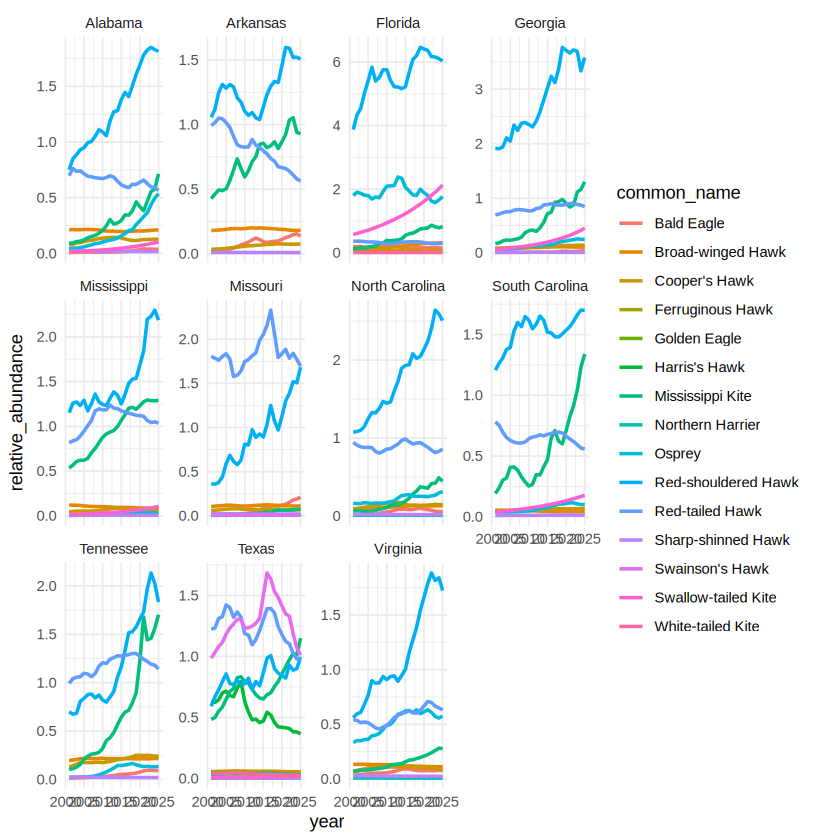

In [ ]:
#Filter by Hawks, Eagles, Kites, and Allies
bbs_data_se_Accipitriformes <- bbs_data_se %>%
  filter(order %in% c("Accipitriformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Accipitriformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~common_region, scales = "free_y")
  labs (title = "Southeastern Hawks, Eagles, Kites, and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

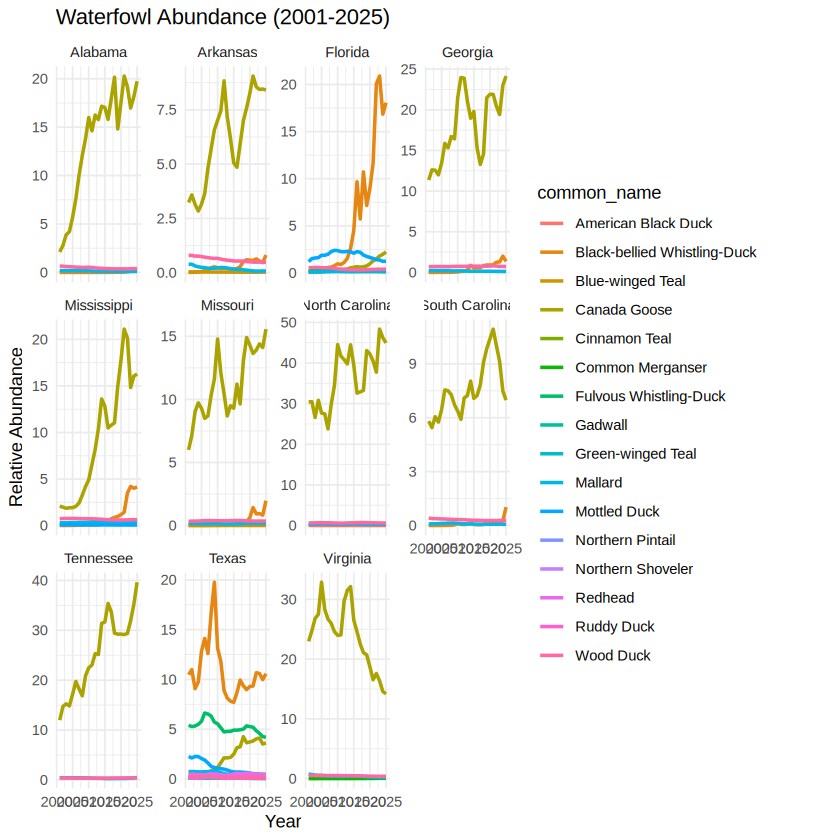

In [ ]:
#Filter by Waterfowl
bbs_data_se_Anseriformes <- bbs_data_se %>%
  filter(order %in% c("Anseriformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Anseriformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~common_region, scales = "free_y") +
  labs (title = "Waterfowl Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

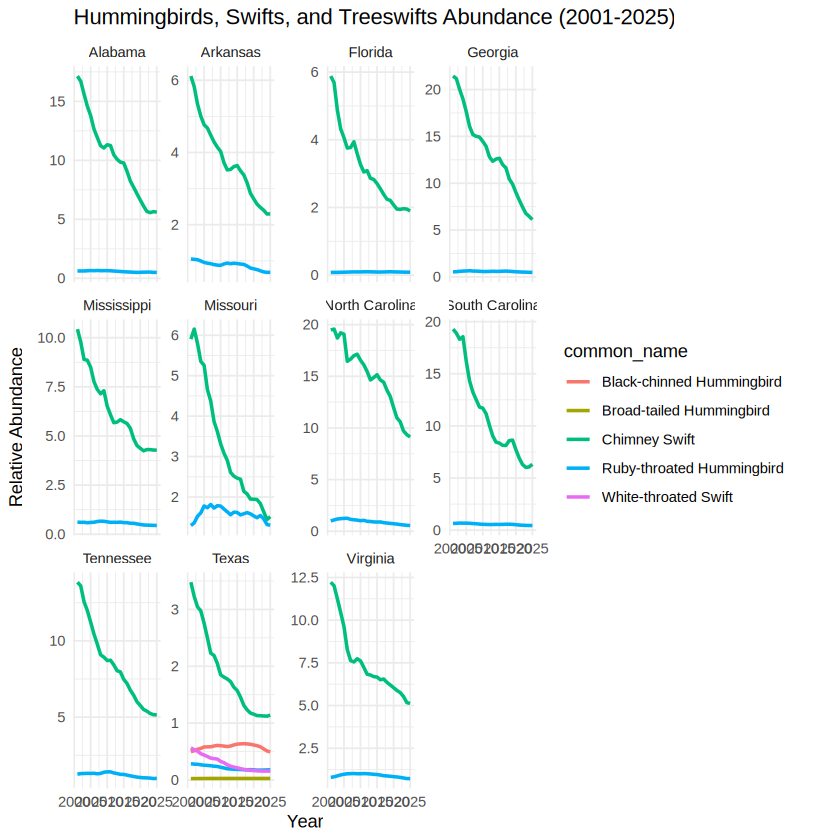

In [ ]:
#Filter by Hummingbirds, Swifts, and Treeswifts
bbs_data_se_Apodiformes <- bbs_data_se %>%
  filter(order %in% c("Apodiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Apodiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~common_region, scales = "free_y") +
  labs (title = "Hummingbirds, Swifts, and Treeswifts Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Nightjars and Nighthawks Abundance (2001-2025)"

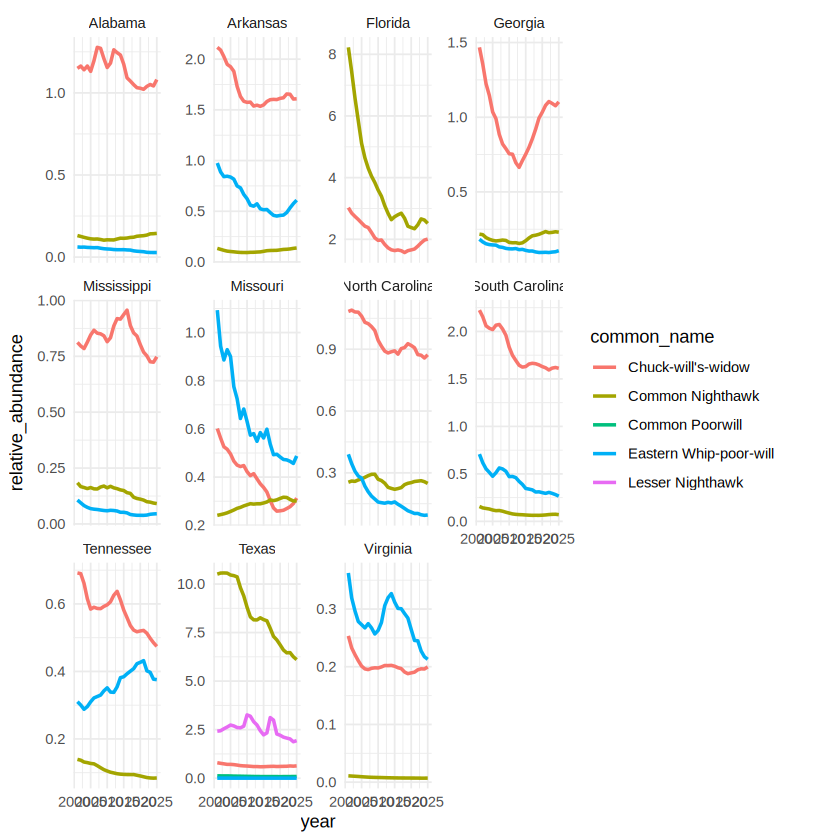

In [ ]:
#Filter by Nightjars and Nighthawks
bbs_data_se_Caprimulgiformes <- bbs_data_se %>%
  filter(order %in% c("Caprimulgiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Caprimulgiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~common_region, scales = "free_y")
  labs (title = "Nightjars and Nighthawks Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

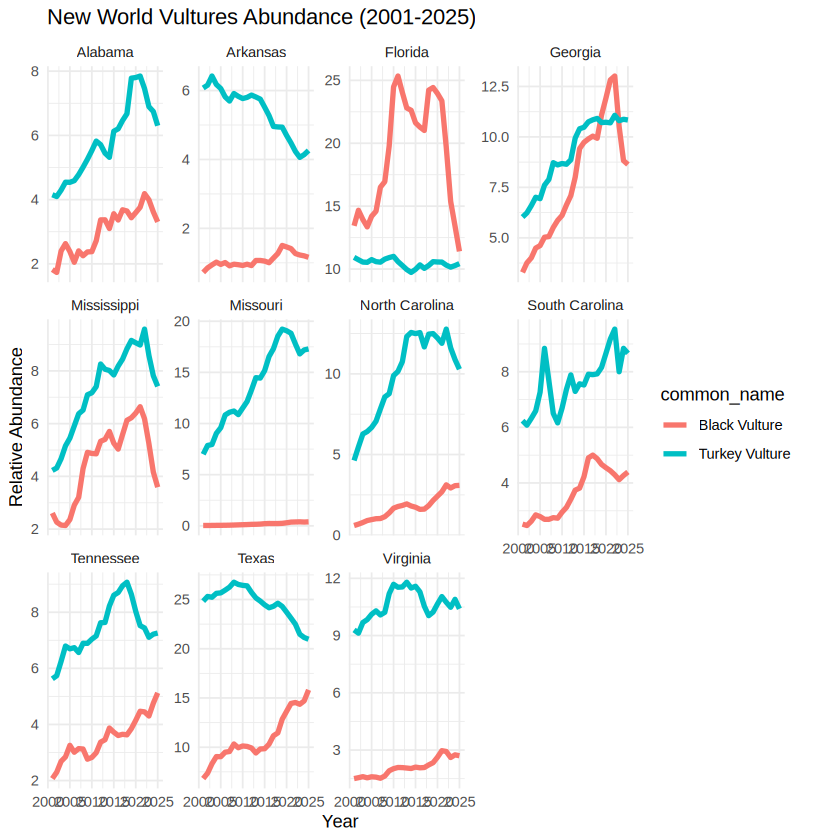

In [ ]:
#Filter by New World Vultures
bbs_data_se_Cathartiformes <- bbs_data_se %>%
  filter(order %in% c("Cathartiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Cathartiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1.5) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "New World Vultures Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

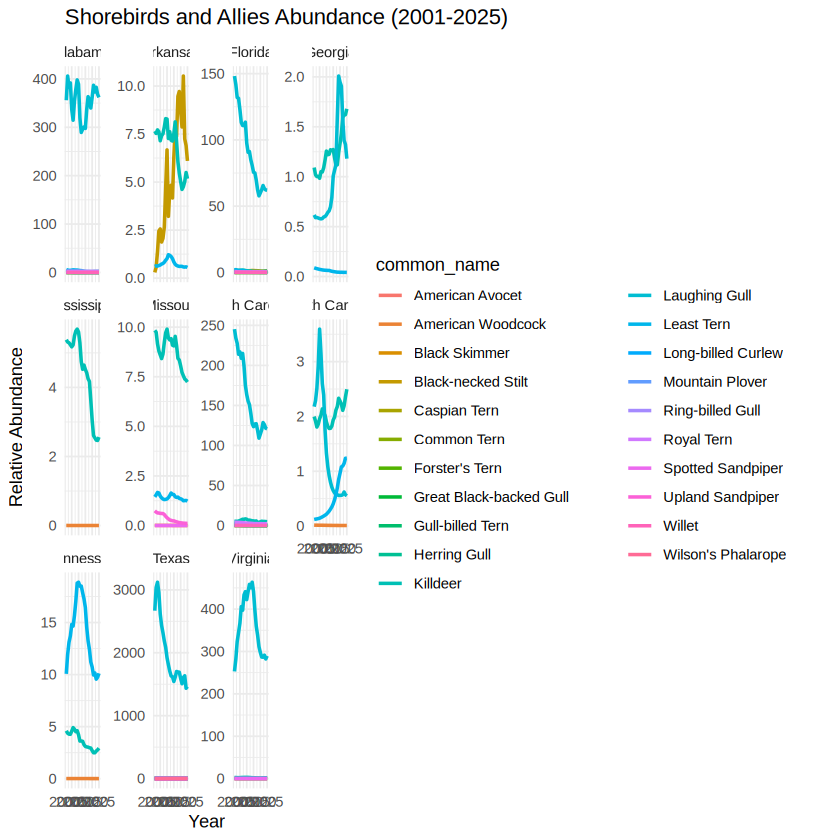

In [ ]:
#Filter by Shorebirds and Allies
bbs_data_se_Charadriiformes <- bbs_data_se %>%
  filter(order %in% c("Charadriiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Charadriiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~common_region, scales = "free_y") +
  labs (title = "Shorebirds and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

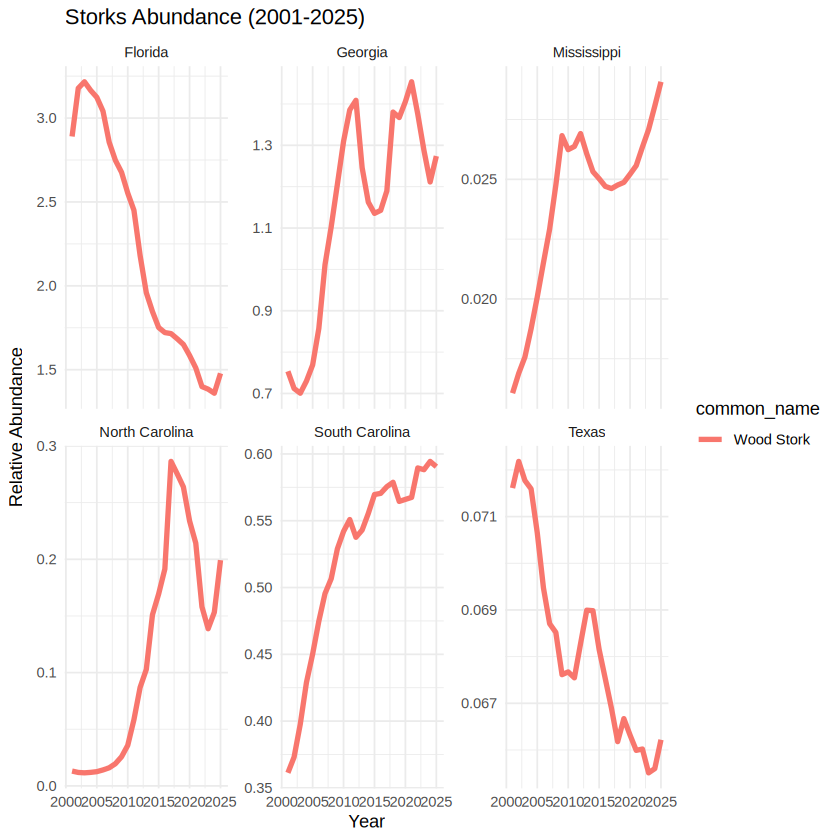

In [ ]:
#Filter by Storks
bbs_data_se_Ciconiiformes <- bbs_data_se %>%
  filter(order %in% c("Ciconiiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Ciconiiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1.5) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Storks Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Pigeons and Doves Abundance (2001-2025)"

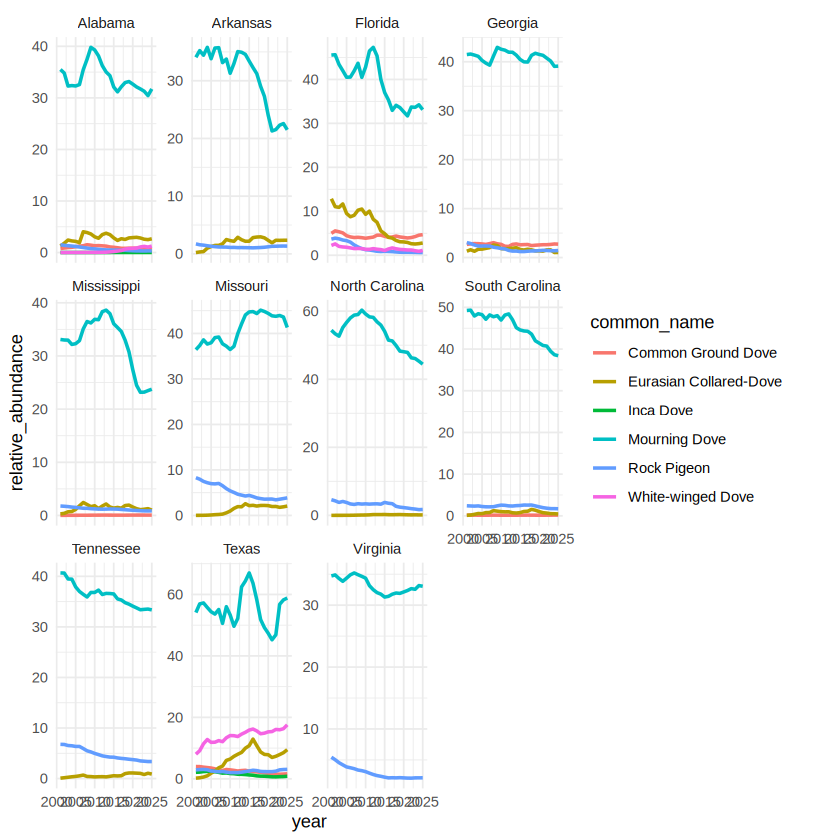

In [ ]:
#Filter by Pigeons and Doves
bbs_data_se_Columbiformes <- bbs_data_se %>%
  filter(order %in% c("Columbiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Columbiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Pigeons and Doves Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Kingfishers and Allies Abundance (2001-2025)"

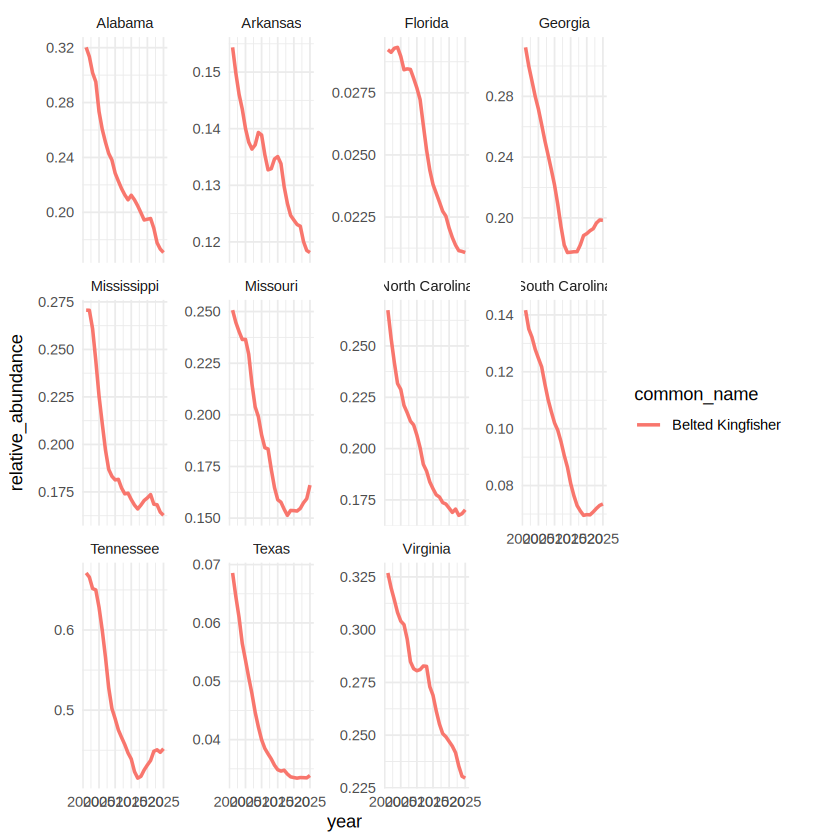

In [ ]:
#Filter by Kingfishers and Allies
bbs_data_se_Coraciiformes <- bbs_data_se %>%
  filter(order %in% c("Coraciiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Coraciiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Kingfishers and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

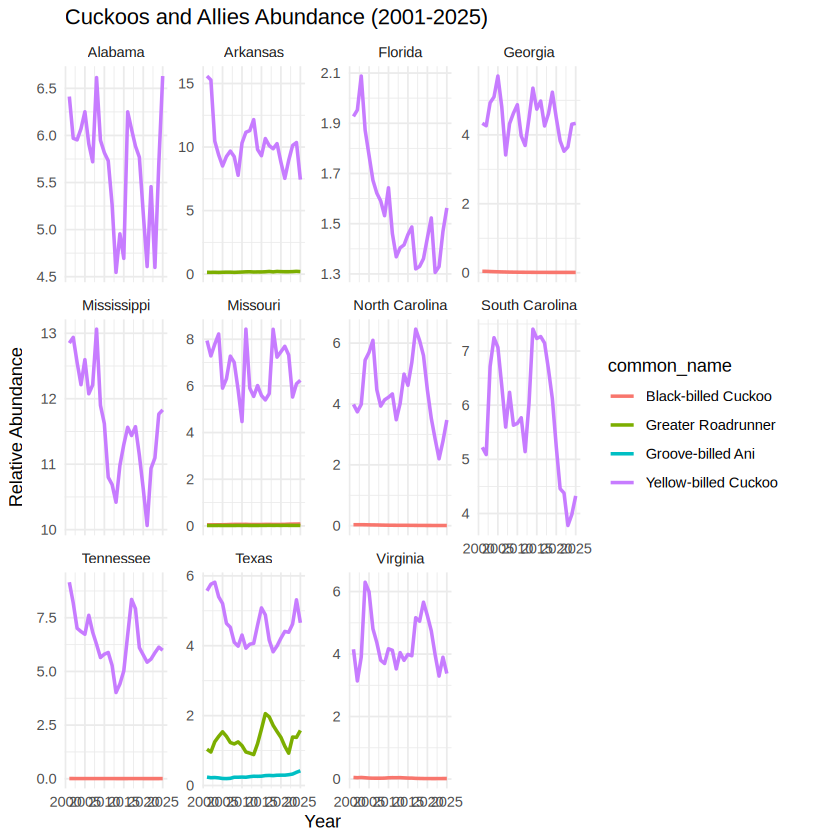

In [ ]:
#Filter by Cuckoos and Allies
bbs_data_se_Cuculiformes <- bbs_data_se %>%
  filter(order %in% c("Cuculiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Cuculiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Cuckoos and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Falcons Abundance (2001-2025)"

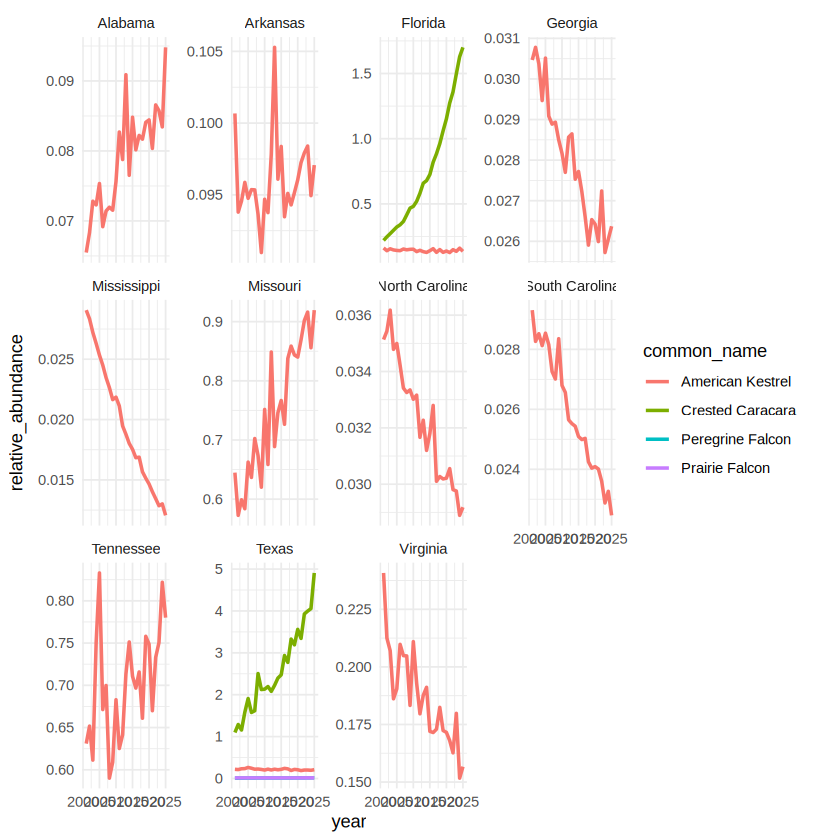

In [ ]:
#Filter by Falcons
bbs_data_se_Falconiformes <- bbs_data_se %>%
  filter(order %in% c("Falconiformes"))

#facetwrap common_region
ggplot(bbs_data_se_Falconiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Falcons Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Landfowl Abundance (2001-2025)"

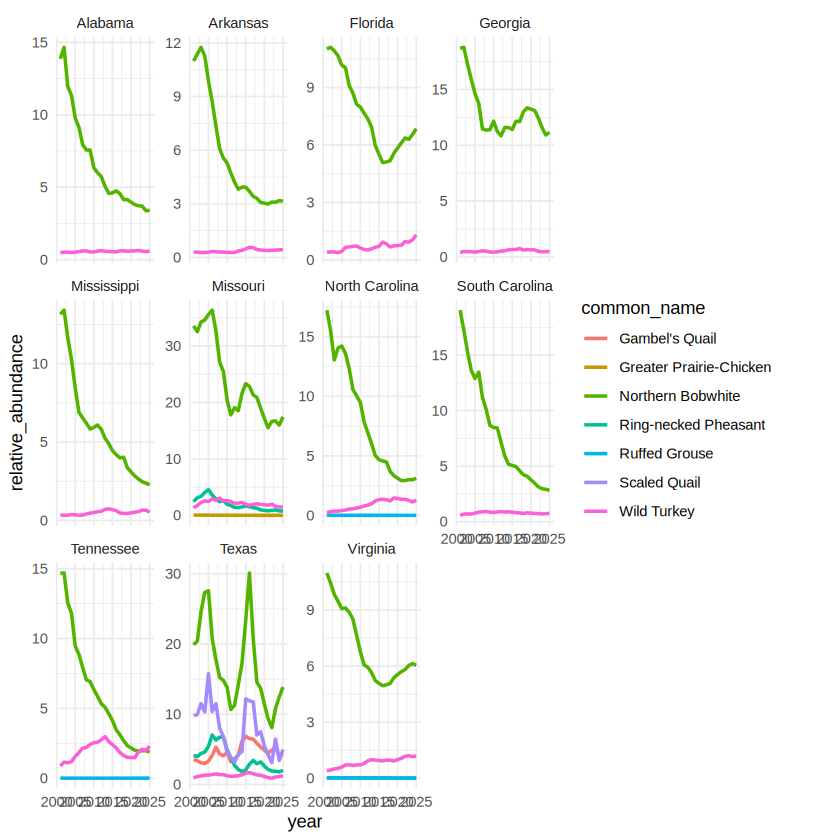

In [ ]:
#Filter by Landfowl
bbs_data_se_Galliformes <- bbs_data_se %>%
  filter(order %in% c("Galliformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Galliformes, aes(y = relative_abundance, x = year, color = common_name)) +
 geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Landfowl Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Cranes, Rails, and Allies Abundance (2001-2025)"

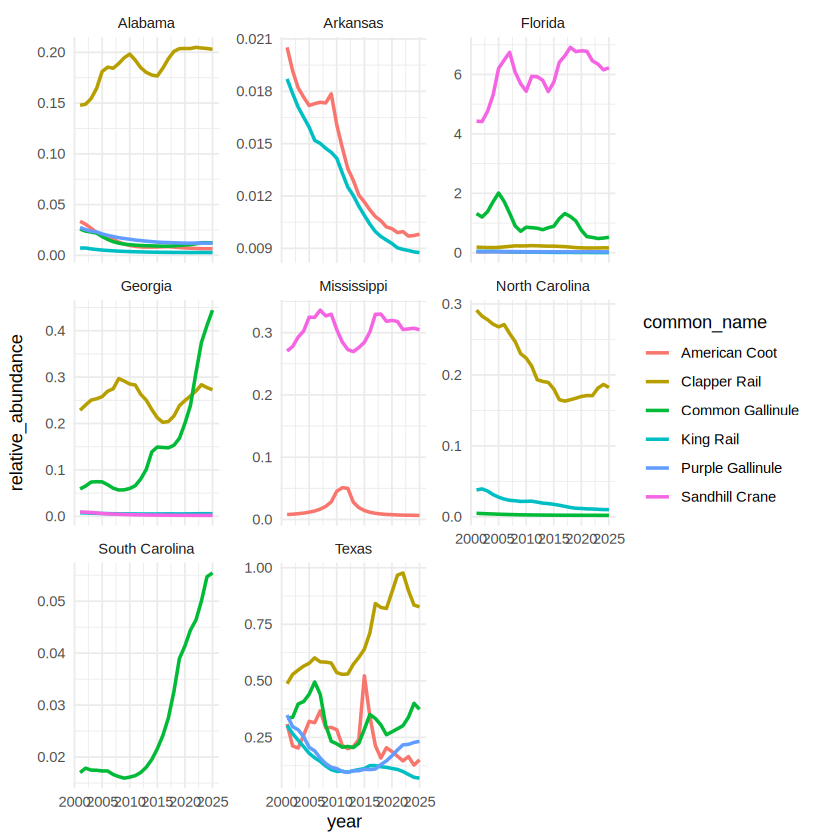

In [ ]:
#Filter by Cranes, Rails, and Allies
bbs_data_se_Gruiformes <- bbs_data_se %>%
  filter(order %in% c("Gruiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Gruiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Cranes, Rails, and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Pelicans, Herons, Ibises, and Allies Abundance (2001-2025)"

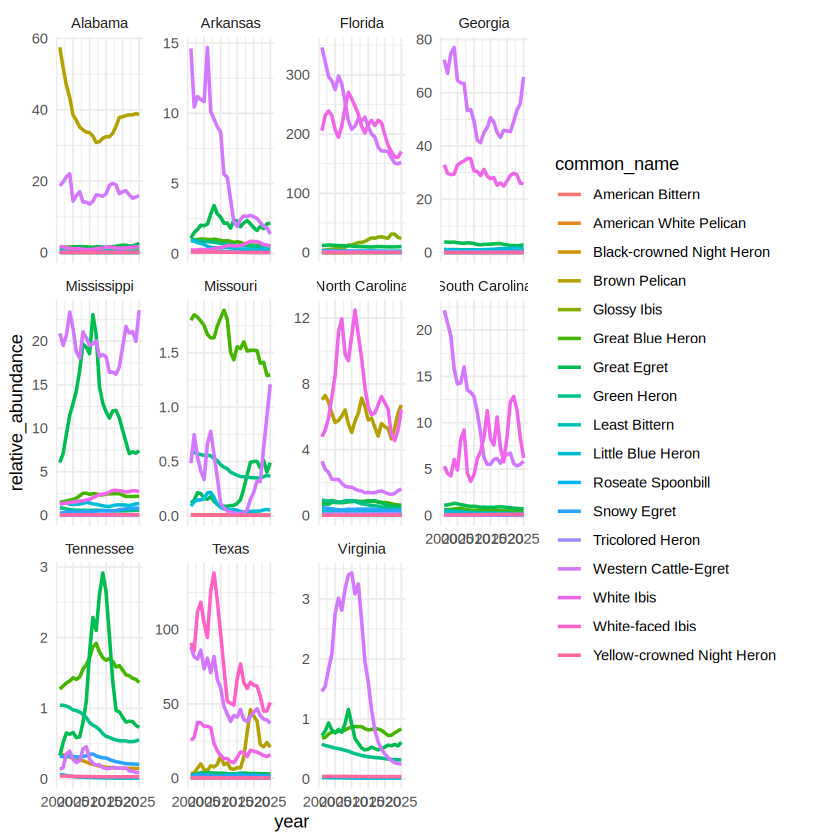

In [ ]:
#Filter by Pelicans, Herons, Ibises, and Allies
bbs_data_se_Pelecaniformes <- bbs_data_se %>%
  filter(order %in% c("Pelecaniformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Pelecaniformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Pelicans, Herons, Ibises, and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

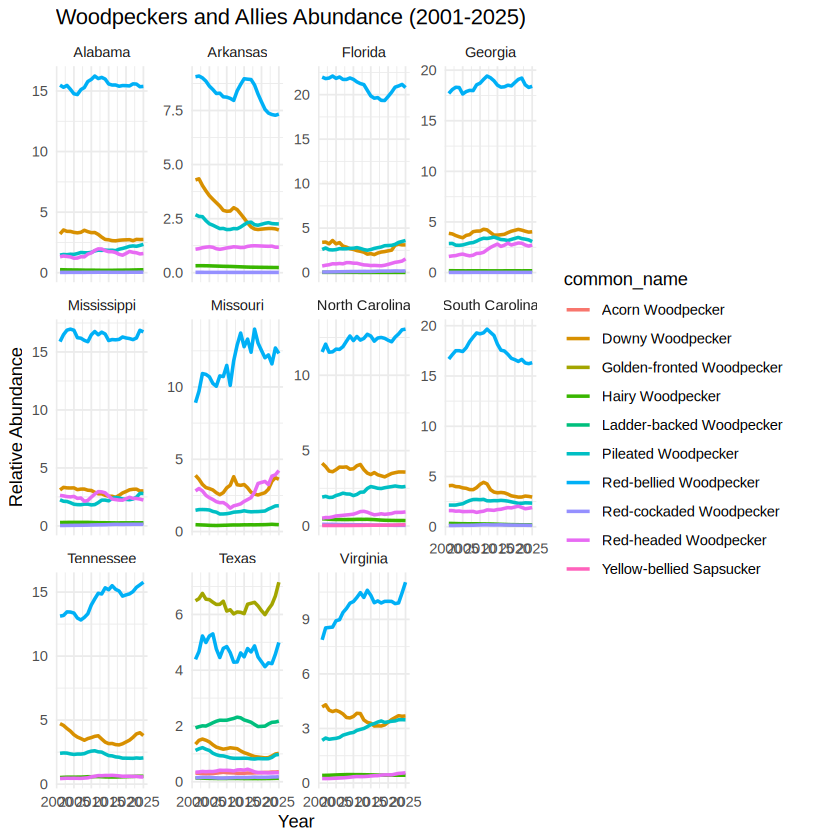

In [ ]:
#Filter by Woodpeckers and Allies
bbs_data_se_Piciformes <- bbs_data_se %>%
  filter(order %in% c("Piciformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Piciformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Woodpeckers and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

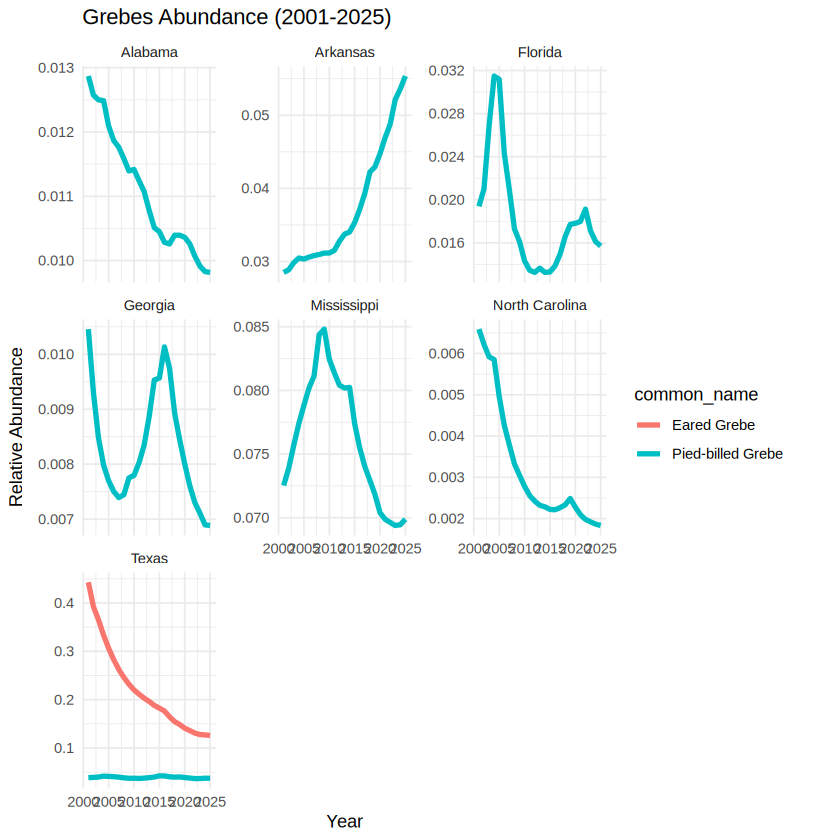

In [ ]:
#Filter by Grebes
bbs_data_se_Podicipediformes <- bbs_data_se %>%
  filter(order %in% c("Podicipediformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Podicipediformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1.5) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Grebes Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

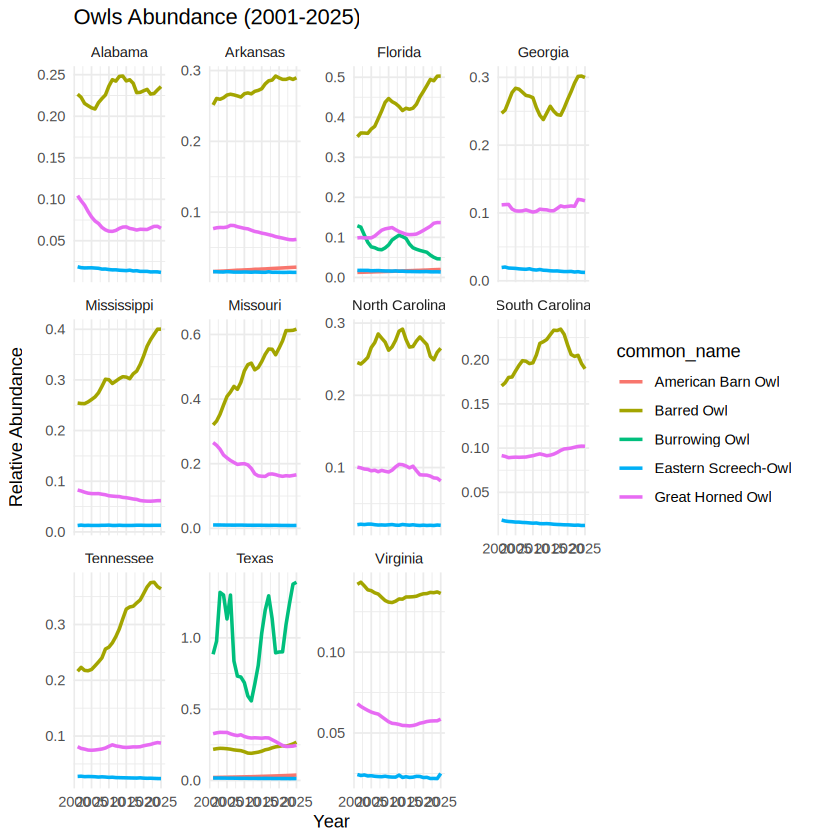

In [ ]:
#Filter by Owls
bbs_data_se_Strigiformes <- bbs_data_se %>%
  filter(order %in% c("Strigiformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Strigiformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
 facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Owls Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

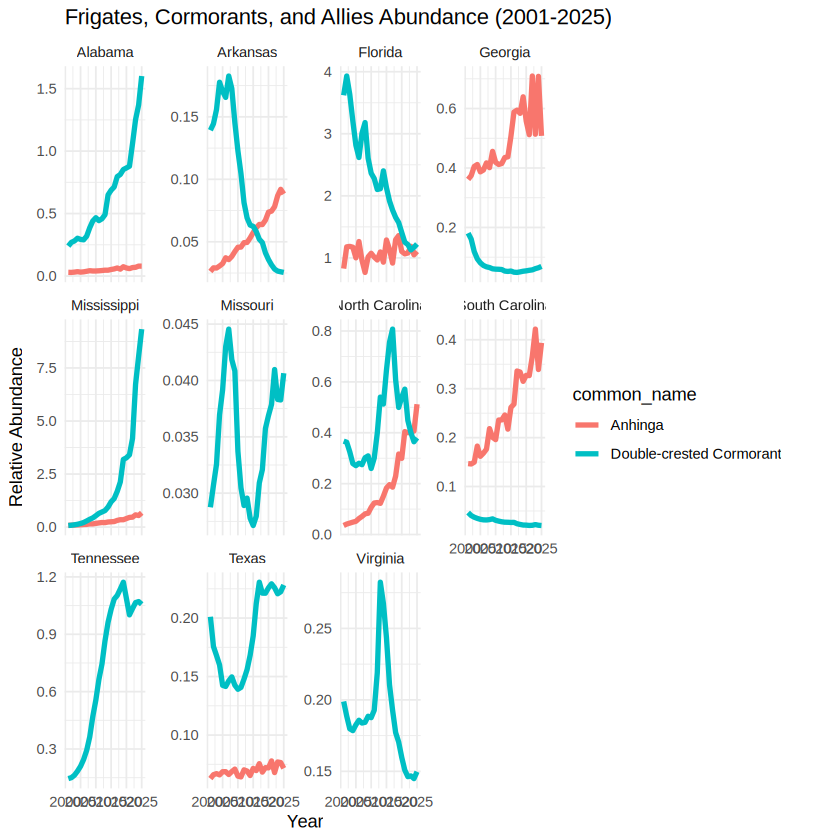

In [ ]:
#Filter by Frigates, Cormorants, and Allies
bbs_data_se_Suliformes <- bbs_data_se %>%
  filter(order %in% c("Suliformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Suliformes, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1.5) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y") +
  labs (title = "Frigates, Cormorants, and Allies Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

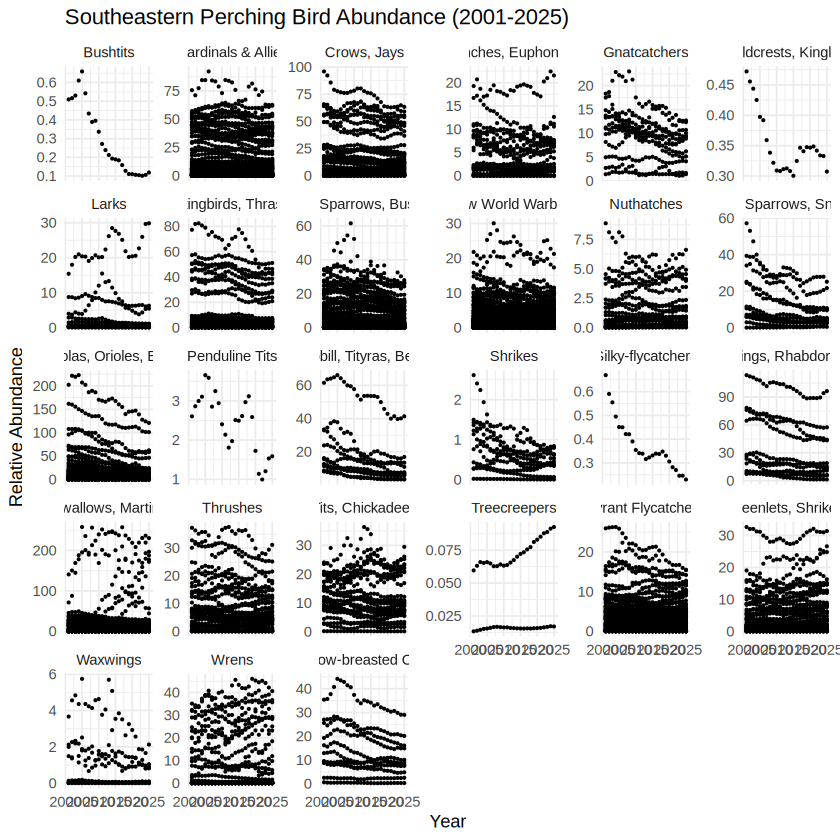

In [ ]:
#Filter by Perching Birds
bbs_data_se_Passeriformes <- bbs_data_se %>%
  filter(order %in% c("Passeriformes"))

#facetwrap by Perching Birds, Orders
ggplot(bbs_data_se_Passeriformes, aes(y = relative_abundance, x = year)) +
  geom_point(size = .5) +
  theme_minimal() +
  facet_wrap(~ common_family, scales = "free_y") +
  labs (title = "Southeastern Perching Bird Abundance (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

<ggplot2::labels> List of 3
 $ y    : chr "Relative Abundance"
 $ x    : chr "Year"
 $ title: chr "Specific Southeastern Bird Indices (2001-2025)"

'data.frame':	275 obs. of  25 variables:
 $ common_name       : chr  "Pileated Woodpecker" "Pileated Woodpecker" "Pileated Woodpecker" "Pileated Woodpecker" ...
 $ order             : chr  "Piciformes" "Piciformes" "Piciformes" "Piciformes" ...
 $ family            : chr  "Picidae" "Picidae" "Picidae" "Picidae" ...
 $ genus             : chr  "Dryocopus" "Dryocopus" "Dryocopus" "Dryocopus" ...
 $ species           : chr  "pileatus" "pileatus" "pileatus" "pileatus" ...
 $ common_order      : chr  "Woodpeckers and Allies" "Woodpeckers and Allies" "Woodpeckers and Allies" "Woodpeckers and Allies" ...
 $ common_family     : chr  "Woodpeckers" "Woodpeckers" "Woodpeckers" "Woodpeckers" ...
 $ region            : chr  "ALA" "ALA" "ALA" "ALA" ...
 $ common_region     : chr  "Alabama" "Alabama" "Alabama" "Alabama" ...
 $ year              : int  2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 ...
 $ relative_abundance: num  1.46 1.51 1.49 1.52 1.51 ...
 $ x2.5.ci           : num  1.24 1.28 1.

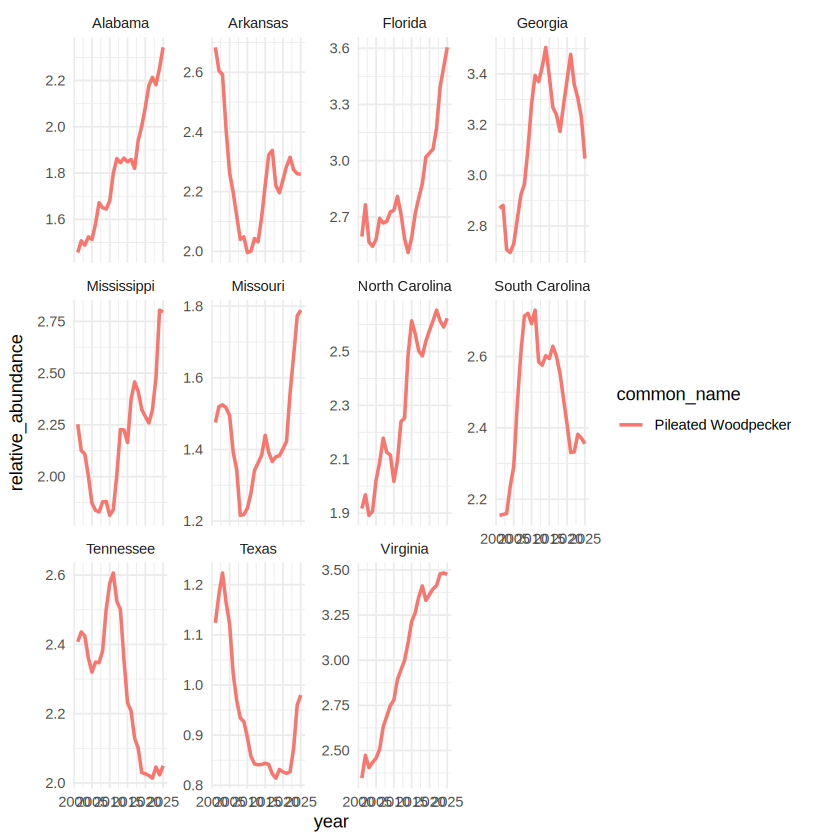

In [ ]:
#filter by specific species. Type in common name to graph

bbs_data_se_bird <- bbs_data_se %>%
  filter(common_name == "Pileated Woodpecker")

#graphing by specific species
ggplot(bbs_data_se_bird, aes(y = relative_abundance, x = year, color = common_name)) +
  geom_line(size = 1) +
  theme_minimal() +
  facet_wrap(~ common_region, scales = "free_y")
  labs (title = "Specific Southeastern Bird Indices (2001-2025)",
  y = "Relative Abundance",
  x = "Year")

  str(bbs_data_se_bird)

**Relative Abundance of Woodpceckers vs Permanent Tree Cover Loss over Time**

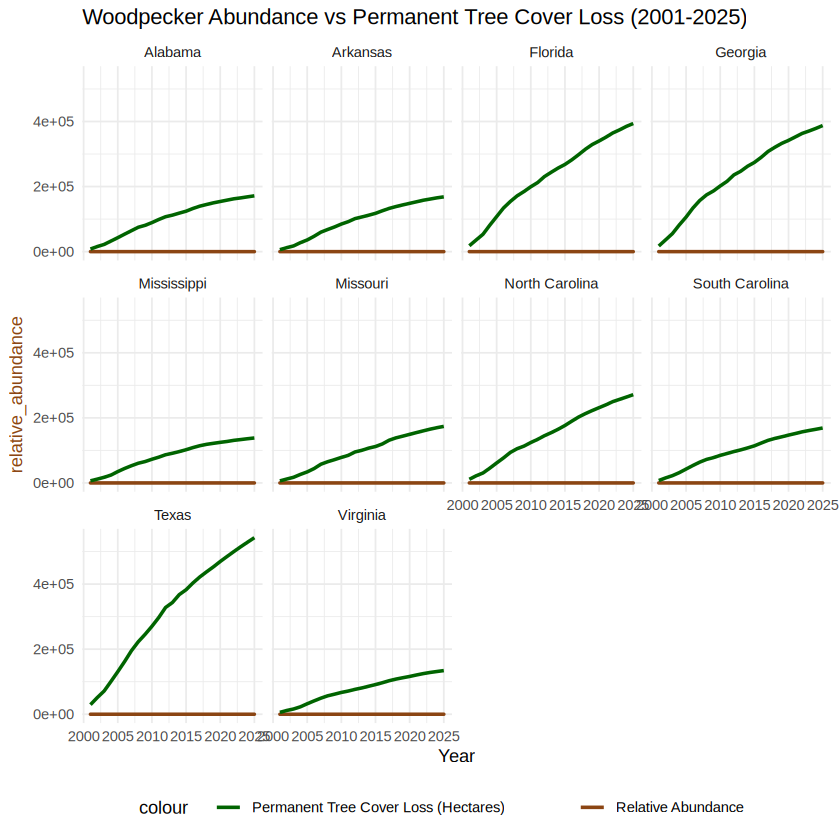

In [6]:
#Filter by Woodpeckers and Allies
bbs_data_se_Piciformes <- bbs_data_se %>%
  filter(order %in% c("Piciformes"))

#facetwrap by common_region
ggplot(bbs_data_se_Piciformes, aes(x = year)) +
  geom_line(aes(y = relative_abundance, color = "Relative Abundance"), linewidth = 1) +
  geom_line(aes(y = cum_perm_loss_ha, #* scale_factor,
  color = "Permanent Tree Cover Loss (Hectares)"), linewidth = 1) +
  facet_wrap(~ common_region) +

#Match axis colors to line colors for readability
  scale_color_manual(values = c("Relative Abundance" = "chocolate4", "Permanent Tree Cover Loss (Hectares)" = "darkgreen")) +
  labs(title = "Woodpecker Abundance vs Permanent Tree Cover Loss (2001-2025)", x = "Year") +
  theme_minimal() +
  theme(
    axis.title.y.left = element_text(color = "chocolate4"),
    axis.title.y.right = element_text(color = "darkgreen"),
    legend.position = "bottom"
  )


